# Model comparison: Logistic regression vs Random forest vs AdaBoost
DSE4212/QF4212 Group Project 1

Run this notebook after the three model notebooks. It reads their saved metrics and test-set probabilities.
Every model used the same 800/200 split, the shared preprocessing pipeline, 5×2 repeated stratified CV
on ROC AUC, thresholds chosen on out-of-fold training predictions and `evaluate()`.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.preprocessing import make_pipeline
from src.evaluation import RANDOM_STATE

OUT = ROOT / "outputs"
TARGET = "credit_risk"
train, test = pd.read_csv(OUT / "train.csv"), pd.read_csv(OUT / "test.csv")
y_test = test[TARGET].astype(int).values

MODELS = {"Logistic regression": "logreg", "Random forest": "rf", "AdaBoost": "adaboost"}
metrics = {m: json.loads((OUT / f"results/{p}_metrics.json").read_text()) for m, p in MODELS.items()}

## Test-set probabilities
Each notebook writes `outputs/predictions/<model>_test_proba.csv`. If the logistic regression file is
missing (it is git-ignored and `logreg_best.joblib` needs scikit-learn ≥ 1.8 to load), the tuned
LR is refitted here from the hyperparameters in `logreg_metrics.json`.

In [2]:
def logreg_proba():
    f = OUT / "predictions/logreg_test_proba.csv"
    if f.exists():
        return pd.read_csv(f)["y_proba"].values
    p = metrics["Logistic regression"]["best_params"]
    pen = {"penalty": "l2"} if p["l1_ratio"] == 0 else {"penalty": "elasticnet", "l1_ratio": p["l1_ratio"]}
    lr = make_pipeline(LogisticRegression(C=p["C"], solver="saga", max_iter=20000,
                                          random_state=RANDOM_STATE, **pen), scale_numeric=True)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        lr.fit(train.drop(columns=[TARGET]), train[TARGET].astype(int))
    proba = lr.predict_proba(test.drop(columns=[TARGET]))[:, 1]
    print(f"LR refitted: test AUC {roc_auc_score(y_test, proba):.4f} "
          f"(notebook reported {metrics['Logistic regression']['results']['LR tuned @ 0.5']['auc']:.4f})")
    return proba

proba = {"Logistic regression": logreg_proba()}
for m, p in list(MODELS.items())[1:]:
    d = pd.read_csv(OUT / f"predictions/{p}_test_proba.csv")
    assert (d["y_true"].values == y_test).all(), f"{p}: test rows out of order"
    proba[m] = d["y_proba"].values

LR refitted: test AUC 0.8163 (notebook reported 0.8163)


## Summary table (tuned models at the cost-optimal threshold, FN:FP = 5:1)

In [3]:
rows = []
for m, js in metrics.items():
    r = next(v for k, v in js["results"].items() if k.endswith("cost-optimal"))
    r05 = next(v for k, v in js["results"].items() if k.endswith("tuned @ 0.5"))
    rows.append({
        "Model": m,
        "CV AUC (mean ± sd)": f"{js['cv_auc_mean']:.3f} ± {js['cv_auc_std']:.3f}",
        "Test AUC [95% CI]": f"{r['auc']:.3f} [{js['test_auc_ci95'][0]:.3f}, {js['test_auc_ci95'][1]:.3f}]",
        "Cost-opt threshold": round(r["threshold"], 3),
        "Recall (defaults)": round(r["recall"], 3),
        "Precision": round(r["precision"], 3),
        "Good clients rejected": f"{r['fp']}/{r['tn'] + r['fp']}",
        "Defaults missed": f"{r['fn']}/{r['fn'] + r['tp']}",
        "Cost @ cost-opt": r["cost"],
        "Cost @ 0.5": r05["cost"],
    })
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "results/model_comparison.csv", index=False)
summary

,Model,CV AUC (mean ± sd),Test AUC [95% CI],Cost-opt threshold,Recall (defaults),Precision,Good clients rejected,Defaults missed,Cost @ cost-opt,Cost @ 0.5
0,Logistic regression,0.769 ± 0.034,"0.816 [0.749, 0.877]",0.188,0.900,0.439,69/140,6/60,99.0,206.0
1,Random forest,0.789 ± 0.037,"0.803 [0.733, 0.870]",0.274,0.917,0.426,74/140,5/60,99.0,141.0
2,AdaBoost,0.768 ± 0.027,"0.818 [0.748, 0.880]",0.364,0.933,0.397,85/140,4/60,105.0,160.0


## Are the AUC differences real?
Paired bootstrap on the 200 test rows: resample rows, recompute each model's AUC on the *same*
resample and take the difference. Pairing removes the variation that all models share, so this
is tighter than comparing the separate confidence intervals.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
names = list(proba)
diffs = {(a, b): [] for i, a in enumerate(names) for b in names[i + 1:]}
n = 0
while n < 2000:
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test[idx].min() == y_test[idx].max():
        continue
    auc = {m: roc_auc_score(y_test[idx], proba[m][idx]) for m in names}
    for (a, b) in diffs:
        diffs[(a, b)].append(auc[a] - auc[b])
    n += 1

pd.DataFrame([{
    "Comparison": f"{a} − {b}",
    "AUC difference": round(roc_auc_score(y_test, proba[a]) - roc_auc_score(y_test, proba[b]), 3),
    "95% CI": f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]",
    "P(diff > 0)": round(float(np.mean(np.array(d) > 0)), 2),
} for (a, b), d in diffs.items()])

,Comparison,AUC difference,95% CI,P(diff > 0)
0,Logistic regression − Random forest,0.014,"[-0.019, +0.044]",0.81
1,Logistic regression − AdaBoost,-0.001,"[-0.036, +0.033]",0.45
2,Random forest − AdaBoost,-0.015,"[-0.047, +0.014]",0.17


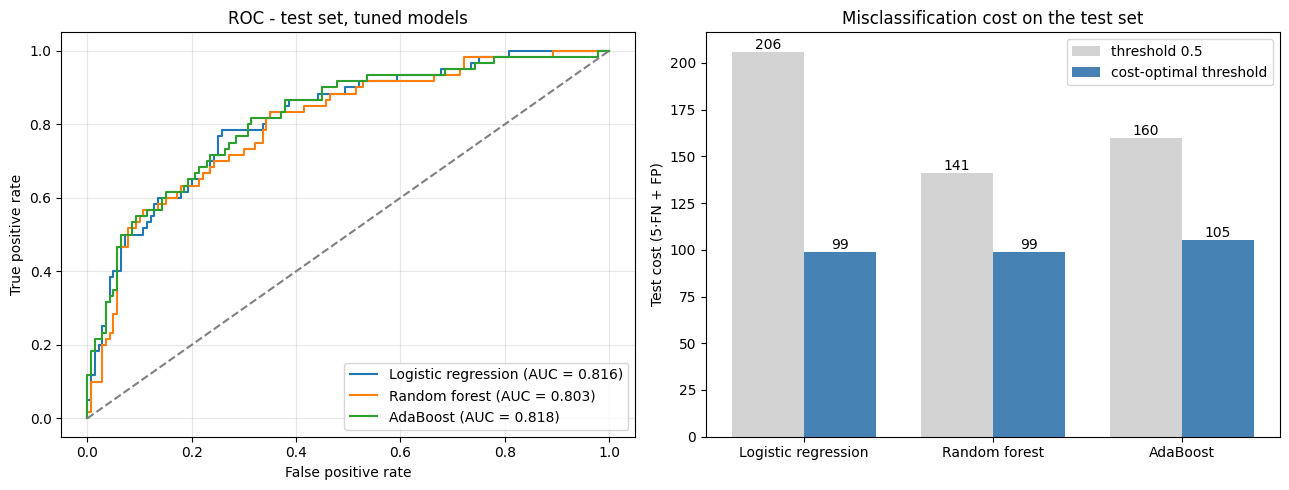

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in names:
    fpr, tpr, _ = roc_curve(y_test, proba[m])
    axes[0].plot(fpr, tpr, label=f"{m} (AUC = {roc_auc_score(y_test, proba[m]):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC - test set, tuned models")
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

x = np.arange(len(names)); w = 0.38
c05 = [next(v for k, v in metrics[m]["results"].items() if k.endswith("tuned @ 0.5"))["cost"] for m in names]
cco = [next(v for k, v in metrics[m]["results"].items() if k.endswith("cost-optimal"))["cost"] for m in names]
b1 = axes[1].bar(x - w / 2, c05, w, label="threshold 0.5", color="lightgray")
b2 = axes[1].bar(x + w / 2, cco, w, label="cost-optimal threshold", color="steelblue")
axes[1].bar_label(b1); axes[1].bar_label(b2)
axes[1].set_xticks(x, names)
axes[1].set(ylabel="Test cost (5·FN + FP)", title="Misclassification cost on the test set")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT / "results/model_comparison.png", dpi=200)
plt.show()

## Conclusions
- **No model is clearly better at ranking borrowers.** Test AUCs are 0.803–0.818 and every paired AUC
  difference has a 95% CI that contains 0. Random forest has the best CV AUC (0.789) but the lowest
  test AUC, and AdaBoost the reverse. This 200-row test set cannot separate the three models.
- **The threshold matters far more than the model.** Moving from 0.5 to the cost-optimal threshold
  cuts the test cost by 30–50% for every model (LR 206 → 99, RF 141 → 99, AdaBoost 160 → 105).
  All three models catch 90–93% of defaulters, at the price of rejecting about half of the good clients.
- **Class imbalance.** Reweighting classes during training barely changed the forest's AUC and hurt
  AdaBoost's. The effective lever for the 30% default rate and the 5:1 cost ratio is the decision threshold.
- **The models agree on what matters:** checking-account status, loan duration and amount, credit
  history, and (for the trees) other instalment plans and loan purpose.
- **Recommendation:** at equal cost, logistic regression is the simplest model to explain and
  audit, with coefficients and odds ratios. The tree ensembles do not earn their extra complexity on this dataset.